# Neural networks: handwritten digits (Keras)
A simple classroom example matching the lecture: **64 inputs → 16 ReLU neurons → 10 softmax probabilities**.

In [5]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

## 1. Load the CSV
Each row contains 64 pixel values (0–16) and the correct digit.

In [6]:
df = pd.read_csv("Handwritten_Digits_8x8_Dataset.csv")
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (1797, 65)


,pixel_00,pixel_01,pixel_02,pixel_03,pixel_04,pixel_05,pixel_06,pixel_07,pixel_08,pixel_09,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


<class 'pandas.DataFrame'>
RangeIndex: 1797 entries, 0 to 1796
Data columns (total 65 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pixel_00  1797 non-null   float64
 1   pixel_01  1797 non-null   float64
 2   pixel_02  1797 non-null   float64
 3   pixel_03  1797 non-null   float64
 4   pixel_04  1797 non-null   float64
 5   pixel_05  1797 non-null   float64
 6   pixel_06  1797 non-null   float64
 7   pixel_07  1797 non-null   float64
 8   pixel_08  1797 non-null   float64
 9   pixel_09  1797 non-null   float64
 10  pixel_10  1797 non-null   float64
 11  pixel_11  1797 non-null   float64
 12  pixel_12  1797 non-null   float64
 13  pixel_13  1797 non-null   float64
 14  pixel_14  1797 non-null   float64
 15  pixel_15  1797 non-null   float64
 16  pixel_16  1797 non-null   float64
 17  pixel_17  1797 non-null   float64
 18  pixel_18  1797 non-null   float64
 19  pixel_19  1797 non-null   float64
 20  pixel_20  1797 non-null   float64
 21  pi

## 2. Prepare inputs and labels
Divide by 16 to convert pixel values to the range 0–1.

In [11]:
X = df.drop(columns="digit").to_numpy(dtype="float32") / 16.0
y = df["digit"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Training:", X_train.shape, "Test:", X_test.shape)

Training: (1437, 64) Test: (360, 64)


## 3. Build the network
`Dense` means each neuron is connected to every neuron in the previous layer.

In [7]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(64,)),              # 64 pixel inputs
    tf.keras.layers.Dense(16, activation="relu"),    # 16 hidden neurons
    tf.keras.layers.Dense(10, activation="softmax")  # 10 digit probabilities
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,210 (4.73 KB)

 Trainable params: 1,210 (4.73 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Choose loss and optimizer
Sparse categorical cross-entropy works with integer labels 0–9. Adam is a gradient-based optimizer.

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 5. Train
Keras performs the forward pass, computes loss, backpropagates gradients and updates weights.

In [12]:
history = model.fit(
    X_train, y_train, epochs=50, batch_size=32, verbose=1
)
print("Final training accuracy:", round(history.history["accuracy"][-1], 3))

Epoch 1/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1378 - loss: 2.2995
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3236 - loss: 2.0910
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4753 - loss: 1.8653
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5616 - loss: 1.6345
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6465 - loss: 1.4004
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7425 - loss: 1.1941
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8100 - loss: 1.0197
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8539 - loss: 0.8734
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8845 - loss: 0.7504
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8977 - loss: 0.6457
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9061 - loss: 0.5615
Epoch 12/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9130 - lo

## 6. Evaluate and predict
Softmax returns 10 probabilities for each image.

In [8]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, verbose=0)
predicted_digits = np.argmax(probabilities, axis=1)

print("Test accuracy:", round(accuracy, 3))
print("Actual digit:", y_test[0])
print("Predicted digit:", predicted_digits[0])
print("10 probabilities:", probabilities[0].round(3))

Test accuracy: 0.981
Actual digit: 5
Predicted digit: 5
10 probabilities: [0.    0.    0.    0.    0.    0.978 0.    0.    0.001 0.021]


## 7. View one digit and its predicted probabilities

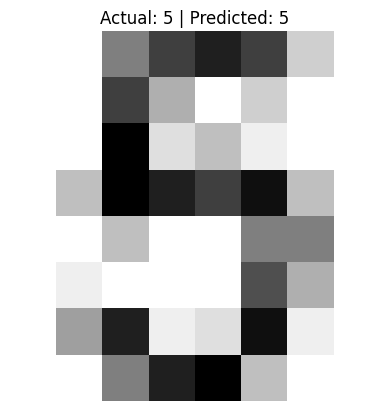

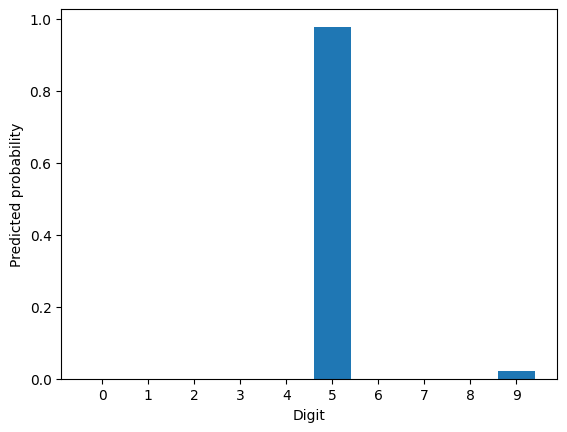

In [9]:
import matplotlib.pyplot as plt

plt.imshow(X_test[0].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
plt.title(f"Actual: {y_test[0]} | Predicted: {predicted_digits[0]}")
plt.axis("off")
plt.show()

plt.bar(range(10), probabilities[0])
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Predicted probability")
plt.show()

## 8. Optional: look at the learning curve

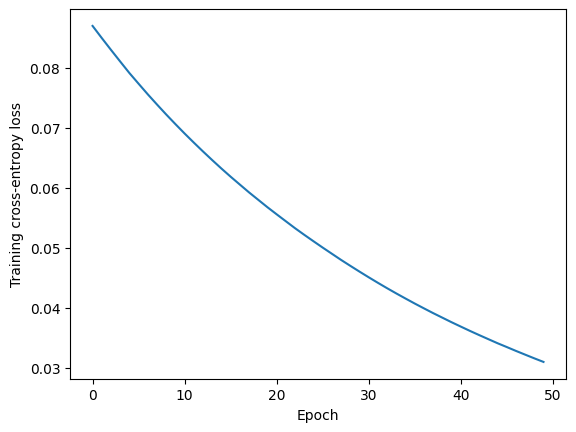

In [10]:
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy loss")
plt.show()